In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score)

X_train = pd.read_csv("../data/processed/X_train_clip.csv")
X_test = pd.read_csv("../data/processed/X_test_clip.csv")
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()


In [5]:
def score_model(name, model, X_te, y_te):
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    print(f"{name}")
    print("  Accuracy :", round(accuracy_score(y_te, pred), 3))
    print("  Precision:", round(precision_score(y_te, pred, zero_division=0), 3))
    print("  Recall   :", round(recall_score(y_te, pred), 3))
    print("  F1       :", round(f1_score(y_te, pred), 3))
    print("  ROC-AUC  :", round(roc_auc_score(y_te, proba), 3))

In [6]:
# Decision Tree
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

tree = GridSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=42),
    {"max_depth": [3, 5, 7, 10], "min_samples_leaf": [5, 20, 50]},
    cv=cv, scoring="roc_auc"
)
tree.fit(X_train, y_train)

print("Best settings:", tree.best_params_)
print("Cross-validation ROC-AUC:", round(tree.best_score_, 3))
score_model("Decision Tree", tree.best_estimator_, X_test, y_test)

Best settings: {'max_depth': 5, 'min_samples_leaf': 20}
Cross-validation ROC-AUC: 0.82
Decision Tree
  Accuracy : 0.691
  Precision: 0.113
  Recall   : 0.808
  F1       : 0.198
  ROC-AUC  : 0.799


In [7]:
# Random Forest (this one can take a few minutes)
forest = GridSearchCV(
    RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                           random_state=42, n_jobs=-1),
    {"max_depth": [5, 10, None], "min_samples_leaf": [1, 5]},
    cv=cv, scoring="roc_auc"
)
forest.fit(X_train, y_train)

print("Best settings:", forest.best_params_)
print("Cross-validation ROC-AUC:", round(forest.best_score_, 3))
score_model("Random Forest", forest.best_estimator_, X_test, y_test)

Best settings: {'max_depth': None, 'min_samples_leaf': 5}
Cross-validation ROC-AUC: 0.861
Random Forest
  Accuracy : 0.959
  Precision: 0.833
  Recall   : 0.152
  F1       : 0.256
  ROC-AUC  : 0.876


Attr27    0.053
Attr24    0.050
Attr26    0.044
Attr46    0.034
Attr16    0.031
Attr13    0.029
Attr34    0.025
Attr6     0.022
Attr5     0.022
Attr25    0.020
dtype: float64


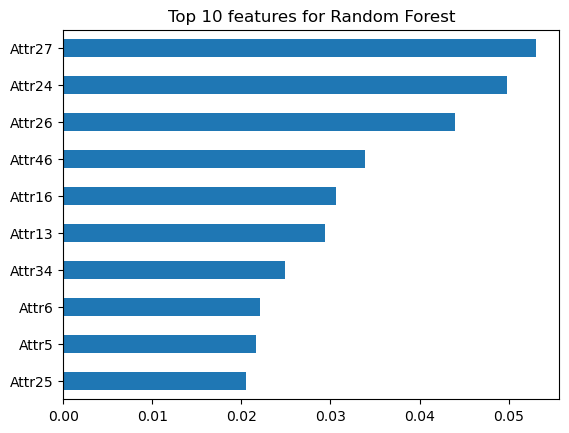

In [8]:
# Which features did the forest find most useful?
importance = pd.Series(forest.best_estimator_.feature_importances_, index=X_train.columns)
top = importance.sort_values(ascending=False).head(10)
print(top.round(3))

top.sort_values().plot(kind="barh")
plt.title("Top 10 features for Random Forest")
plt.show()